# Ramen's update direction agrees with the cross-entropy gradient for most samples, but only a little more than a sample-agnostic direction does

*2026-11-06. Week 01. Plan: `docs/plans/grad_alignment.md`. ORACLE diagnostic: it reads true labels to build the reference gradient, and changes no prediction.*

**Question.** How often does the direction Ramen steps in point the same way as the cross-entropy (CE) gradient toward the true label?
**Hypothesis (from the plan).** On CIFAR-10-C seed 0, for most samples cos(g_R, g_CE) > 0 and above a shuffled null; it is lower on samples zero-shot CLIP gets wrong.

**Variants**
| name | class | config | what it changes | uses labels? |
|---|---|---|---|---|
| Ramen | upstream `Ramen` | `cfg/<dataset>/Ramen.yaml` | baseline | no |
| RamenGradAlignment | `ramen_lab.methods.grad_alignment.RamenGradAlignment` | Ramen's yaml + `probe_path` (loss scale 1024) | nothing in the update; probes only | **ORACLE** (probe only) |

**Data.** CIFAR-10-C, CIFAR-100-C, ImageNet-C (5k per corruption) at severity 5: 15 corruptions each; DomainNet: 6 domains. Mixed stream.
**Backbone / batch.** CIFAR-10-C: ViT-B/32, batch 100. CIFAR-100-C and ImageNet-C: ViT-B/16, batches 32 and 24. DomainNet: ViT-B/32, batch 32. Frozen per dataset (D18).
**Seeds.** 0 only (a seed changes only the stream order). **How produced.** `python grad_alignment.py run <DATASET> --seed 0`; resources are in the sanity section.
**What counts.** Diagnostic only, no accuracy gate. Alignment is read against two reference lines: the shuffled null and the sample's own entropy gradient.

## How Ramen adapts, and what is measured

For a sample $x_i$ in a batch, with zero-shot LayerNorm affine parameters $\theta_0$ (each sample has its own copy, `BySampleLayerNorm`, `src/models/ModelForBySampleTTA.py`):

**1. Own entropy gradient** (`src/methods/Ramen.py`, `forward`: loss, backward, `get_by_sample_grad`)
$$g_i^{H} = \nabla_{\theta_i} H(p_i)\big|_{\theta_0},\qquad p_i = \mathrm{softmax}(100\, z_i^\top W^\top)$$

**2. Memory and retrieval** (`Ramen.forward`: `cache.add`, `cache.query`): the aggregated gradient fed to the optimizer
$$g_i^{R} = G_i = \frac{1}{|\mathcal C^+|}\sum_{c\in\mathcal C^+}\ \sum_{j\in \mathrm{top}k_c(z_i)} e^{-H_j}e^{-\beta\lVert z_i-z_j\rVert}\ g_j^{H}$$

**3. Applied step** (`src/models/optimizer.py`, SignSGD, no momentum): $\theta_i = \theta_0 - \eta\,\mathrm{sign}(g_i^{R})$.

**The reference (ORACLE, never used by the update)** (`RamenGradAlignment._ce_grad`):
$$g_i^{CE} = \nabla_{\theta_i}\,\mathrm{CE}(p_i, y_i)\big|_{\theta_0}$$

**Measured per sample** (`RamenGradAlignment._record`), with $\cos(a,b)=\frac{a\cdot b}{\lVert a\rVert\lVert b\rVert}$ over all LayerNorm affine coordinates:
- $\cos(g^R, g^{CE})$, and $\cos(\mathrm{sign}\,g^R, g^{CE})$, the step actually taken (the sign changes the direction);
- $\cos(g^H, g^{CE})$, the sample's own entropy gradient: the reference that Tent-style adaptation would use;
- the **null** $\cos(g^R_i, g^{CE}_{\pi(i)})$ with $\pi$ = the previous sample in the batch (a different, random-label sample): what a direction that is not specific to the sample scores.
- the first-order change of CE from the step, $-\eta\langle \mathrm{sign}\,g^R, g^{CE}\rangle$, and the realised CE before and after the step.

A positive cosine means the descent step along $-g^R$ also lowers CE to first order.

**Why it could mislead.**
1. fp16 CE gradients of confident samples underflow. Mitigated by loss scale 1024; a scale 1 vs 1024 check on a subset agreed within 0.014 and had 0% undefined cosines.
2. $\cos(g^R, g^{CE})$ well above 0 can come from a generic direction shared by all samples. This is why the null is plotted beside it.
3. Cosines in about 40k dimensions are driven by a few large coordinates; sign agreement is reported as a check.
4. The CE gradient is taken at $\theta_0$, the same point where $g^H$ and the retrieved gradients were taken. The step is one SignSGD step of size $\eta$, so first-order statements hold only for small $\eta$.

In [1]:
%load_ext autoreload
%autoreload 2
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
HERE = Path.cwd()
sys.path.insert(0, str(HERE.parents[2])); sys.path.insert(0, str(HERE))
import grad_alignment as ga
from ramen_lab.analysis.plots import use_style
from ramen_lab.records import load_records, read_metrics
use_style()
RUNS = {"CIFAR-10-C": "C10_{}_b100_s0", "CIFAR-100-C": "C100_{}_b32_s0", "DomainNet": "DN_{}_b32_s0", "ImageNet-C": "INC_{}_b24_s0"}
PROBE = {k: HERE / "results" / ("pc2_" + v.format("RamenGradAlignment")) for k, v in RUNS.items()}
BASE = {k: HERE.parent / "2026-11-01_baseline" / "results" / ("pc2_" + v.format("Ramen")) for k, v in RUNS.items()}
A = {k: ga.load_alignment(p) for k, p in PROBE.items()}
REC = {k: load_records(p) for k, p in PROBE.items()}
NAMES = {k: list(json.loads((p / "metrics.json").read_text())["metrics"]["per_domain"]) for k, p in PROBE.items()}
print({k: f"{len(a['cos_R_CE']):,} samples" for k, a in A.items()})

{'CIFAR-10-C': '150,000 samples', 'CIFAR-100-C': '150,000 samples', 'DomainNet': '586,575 samples', 'ImageNet-C': '75,000 samples'}


## The data
Samples per domain, zero-shot (before any adaptation) accuracy, and Ramen's final accuracy, from the probe runs' own records.

In [2]:
rows = []
for k, a in A.items():
    zs, fin = int(a["zs_correct"].sum()), int(a["final_correct"].sum()); n = len(a["zs_correct"])
    rows.append({"dataset": k, "domains": len(NAMES[k]), "samples": f"{n:,}", "zero-shot correct": f"{zs:,} ({zs/n:.1%})",
                 "zero-shot wrong": f"{n-zs:,} ({(n-zs)/n:.1%})", "Ramen correct": f"{fin:,} ({fin/n:.1%})"})
pd.DataFrame(rows).set_index("dataset")

,domains,samples,zero-shot correct,zero-shot wrong,Ramen correct
dataset,,,,,
CIFAR-10-C,15,"150,000","92,067 (61.4%)","57,933 (38.6%)","108,921 (72.6%)"
CIFAR-100-C,15,"150,000","55,641 (37.1%)","94,359 (62.9%)","69,055 (46.0%)"
DomainNet,6,"586,575","310,131 (52.9%)","276,444 (47.1%)","320,270 (54.6%)"
ImageNet-C,15,"75,000","20,462 (27.3%)","54,538 (72.7%)","24,814 (33.1%)"


## Sanity checks
The probe must be Ramen: same accuracy as the baseline Ramen run with the same seed, batch and GPU. Seed 0's baseline ran on GPU 0. CIFAR-100-C and ImageNet-C probes ran on GPU 1 (the 2080 Ti), so a small prediction difference is the known fp16-kernel difference between GPU models, not the probe (the unit test shows bit-identical logits on one GPU).

In [3]:
key = lambda r: np.lexsort((r["sample_idx"], r["domain_idx"]))
rows = []
for k in A:
    mp, mb = read_metrics(PROBE[k]), read_metrics(BASE[k])
    rp, rb = REC[k], load_records(BASE[k])
    same = float((rp["pred"][key(rp)] == rb["pred"][key(rb)]).mean())
    res = mp["resources"]
    rows.append({"dataset": k, "probe acc": mp["metrics"]["acc"], "Ramen acc (baseline run)": mb["metrics"]["acc"],
                 "predictions identical": f"{same:.2%}", "GPU of probe run": "RTX 2080 Ti" if k in ("CIFAR-100-C", "ImageNet-C") else "RTX 3080 Ti",
                 "peak RAM GB": res["peak_ram_gb"], "peak GPU GB (reserved)": res["peak_gpu_reserved_gb"], "minutes": res["minutes"],
                 "undefined cos(g_R,g_CE)": f"{int(np.isnan(A[k]['cos_R_CE']).sum()):,}"})
pd.DataFrame(rows).set_index("dataset")

,probe acc,Ramen acc (baseline run),predictions identical,GPU of probe run,peak RAM GB,peak GPU GB (reserved),minutes,"undefined cos(g_R,g_CE)"
dataset,,,,,,,,
CIFAR-10-C,72.6140,72.6140,100.00%,RTX 3080 Ti,6.75,9.84,4.71,0
CIFAR-100-C,46.0367,46.0307,95.96%,RTX 2080 Ti,5.79,8.58,26.56,1
DomainNet,57.1417,57.1417,100.00%,RTX 3080 Ti,5.35,9.07,55.87,7
ImageNet-C,33.0853,33.0973,95.09%,RTX 2080 Ti,3.35,8.70,24.82,5


`metrics.json` of these four probe runs names a wrong `baseline_run_id` (e.g. `pc2_CIFAR10C_Ramen_s0`, a bug in the CLI, fixed in `grad_alignment.py`); the baseline runs used above are the existing `pc2_C10_Ramen_b100_s0`-style runs.

## Finding 1: most samples are aligned, but the median cosine is small and only 0.04 to 0.17 above the shuffled null

In [4]:
tbl = []
for k, a in A.items():
    for r in ga.summary_rows(a):
        if r["samples"] == "all":
            tbl.append({"dataset": k, "statistic": r["statistic"], "median": round(r["median"], 3), "mean": round(r["mean"], 3),
                        "cos > 0": f'{r["n_positive"]:,} of {r["n"]:,} ({r["share_positive"]:.1%})'})
pd.DataFrame(tbl).pivot(index="statistic", columns="dataset", values="median").loc[list(ga.STATS.values())]

dataset,CIFAR-10-C,CIFAR-100-C,DomainNet,ImageNet-C
statistic,,,,
"cos(g_R, g_CE)",0.266,0.208,0.106,0.083
"cos(sign g_R, g_CE) [the step taken]",0.088,0.068,0.025,0.029
"cos(g_H, g_CE) [own entropy gradient]",0.932,0.494,0.755,0.208
"null: cos(g_R, other sample's g_CE)",0.097,0.086,0.069,0.044


In [5]:
pd.DataFrame(tbl).set_index(["dataset", "statistic"])[["mean", "cos > 0"]]

mean  \
dataset     statistic                                       
CIFAR-10-C  cos(g_R, g_CE)                          0.237   
            cos(sign g_R, g_CE)  [the step taken]   0.076   
            cos(g_H, g_CE)  [own entropy gradient]  0.488   
            null: cos(g_R, other sample's g_CE)     0.100   
CIFAR-100-C cos(g_R, g_CE)                          0.195   
            cos(sign g_R, g_CE)  [the step taken]   0.066   
            cos(g_H, g_CE)  [own entropy gradient]  0.323   
            null: cos(g_R, other sample's g_CE)     0.082   
DomainNet   cos(g_R, g_CE)                          0.105   
            cos(sign g_R, g_CE)  [the step taken]   0.033   
            cos(g_H, g_CE)  [own entropy gradient]  0.363   
            null: cos(g_R, other sample's g_CE)     0.069   
ImageNet-C  cos(g_R, g_CE)                          0.079   
            cos(sign g_R, g_CE)  [the step taken]   0.030   
            cos(g_H, g_CE)  [own entropy gradient]  0.194   
            null: cos(g_R, other sample's g_CE)     0.042   

                                                                       cos > 0  
dataset     statistic                                                           
CIFAR-10-C  cos(g_R, g_CE)                          117,438 of 150,000 (78.3%)  
            cos(sign g_R, g_CE)  [the step taken]   123,372 of 150,000 (82.2%)  
            cos(g_H, g_CE)  [own entropy gradient]  111,372 of 150,000 (74.2%)  
            null: cos(g_R, other sample's g_CE)     101,468 of 150,000 (67.6%)  
CIFAR-100-C cos(g_R, g_CE)                          110,765 of 149,999 (73.8%)  
            cos(sign g_R, g_CE)  [the step taken]   117,146 of 149,999 (78.1%)  
            cos(g_H, g_CE)  [own entropy gradient]  100,277 of 149,999 (66.9%)  
            null: cos(g_R, other sample's g_CE)      98,911 of 149,999 (65.9%)  
DomainNet   cos(g_R, g_CE)                          389,881 of 586,568 (66.5%)  
            cos(sign g_R, g_CE)  [the step taken]   419,286 of 586,568 (71.5%)  
            cos(g_H, g_CE)  [own entropy gradient]  380,739 of 586,568 (64.9%)  
            null: cos(g_R, other sample's g_CE)     372,624 of 586,568 (63.5%)  
ImageNet-C  cos(g_R, g_CE)                            49,583 of 74,995 (66.1%)  
            cos(sign g_R, g_CE)  [the step taken]     56,433 of 74,995 (75.2%)  
            cos(g_H, g_CE)  [own entropy gradient]    44,053 of 74,995 (58.7%)  
            null: cos(g_R, other sample's g_CE)       45,591 of 74,995 (60.8%)

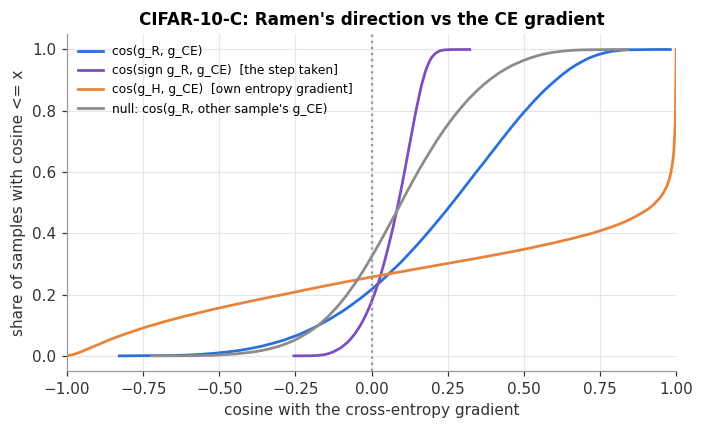

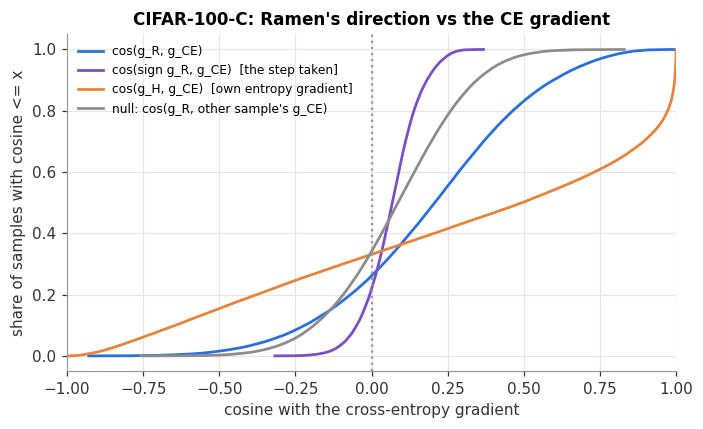

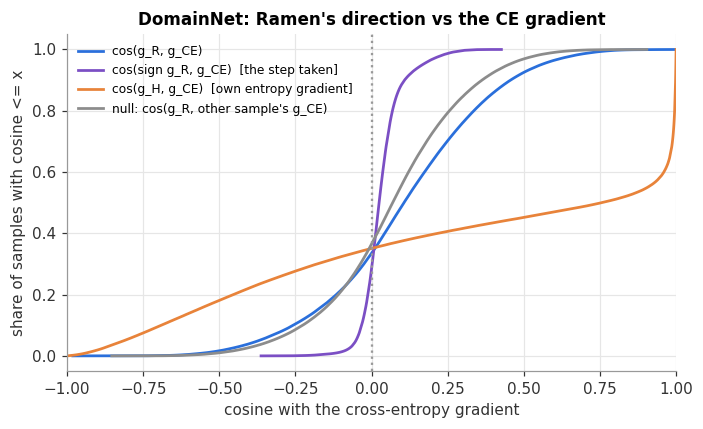

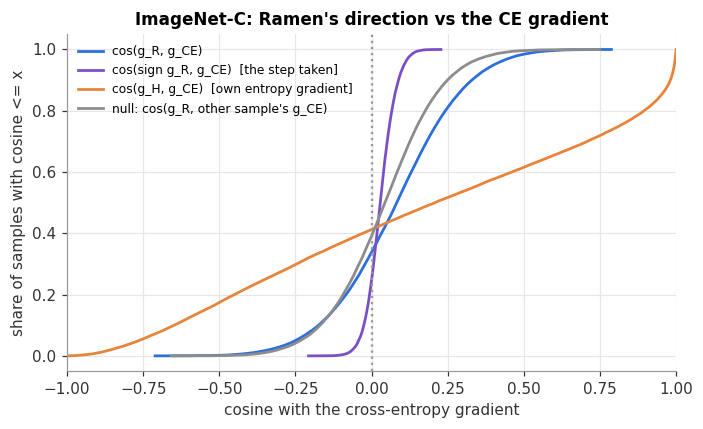

In [6]:
for k, a in A.items():
    ga.ecdf_figure(a, f"{k}: Ramen's direction vs the CE gradient"); plt.show()

## Finding 2: the alignment lives on samples zero-shot already gets right; on the wrong ones it is at the null or below

In [7]:
tbl = []
for k, a in A.items():
    for r in ga.summary_rows(a):
        if r["samples"] != "all" and r["statistic"].startswith(("cos(g_R", "null")):
            tbl.append({"dataset": k, "statistic": r["statistic"][:24], "samples": r["samples"], "n": f'{r["n"]:,}',
                        "median": round(r["median"], 3), "cos > 0": f'{r["share_positive"]:.1%}'})
pd.DataFrame(tbl).pivot_table(index=["dataset", "samples"], columns="statistic", values="median")

statistic                    cos(g_R, g_CE)  null: cos(g_R, other sam
dataset     samples                                                  
CIFAR-10-C  zero-shot right           0.366                     0.102
            zero-shot wrong           0.092                     0.091
CIFAR-100-C zero-shot right           0.434                     0.088
            zero-shot wrong           0.080                     0.086
DomainNet   zero-shot right           0.229                     0.071
            zero-shot wrong          -0.032                     0.067
ImageNet-C  zero-shot right           0.189                     0.043
            zero-shot wrong           0.040                     0.044

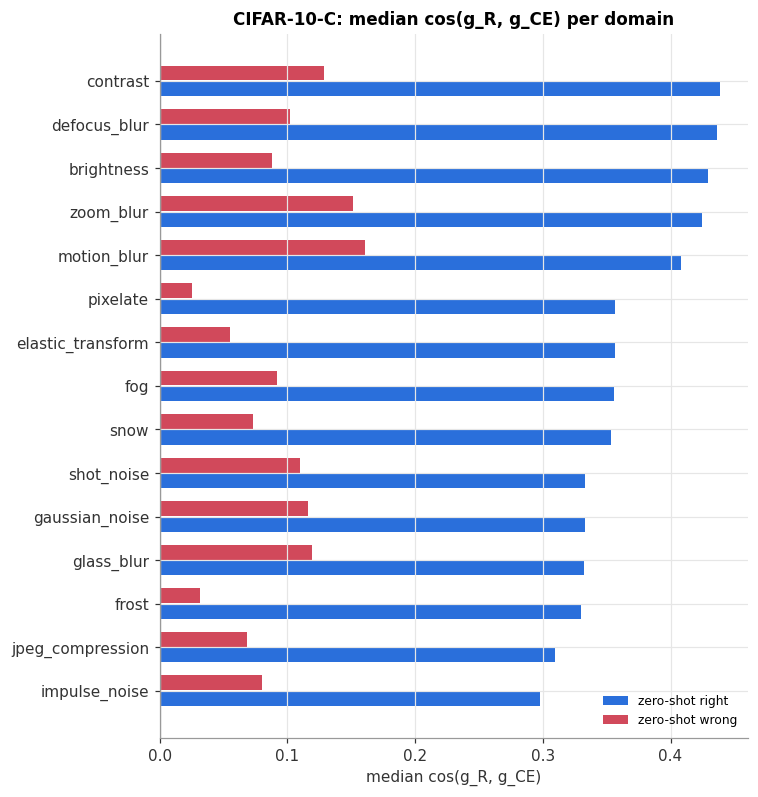

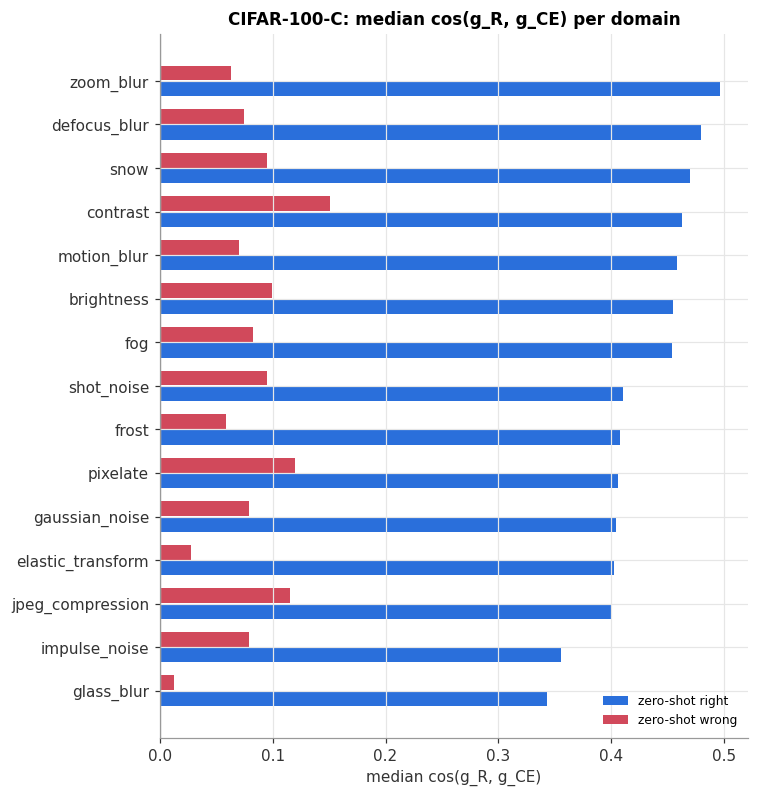

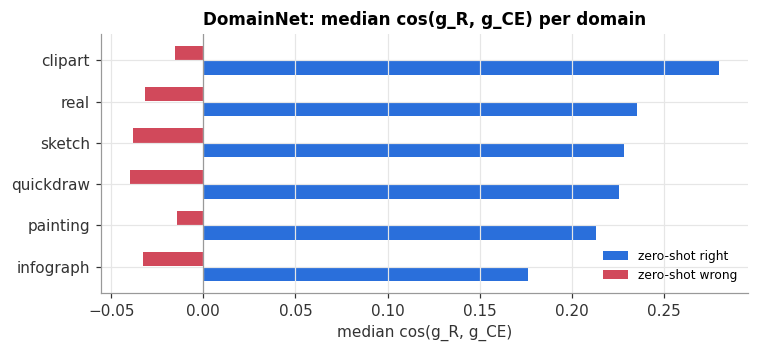

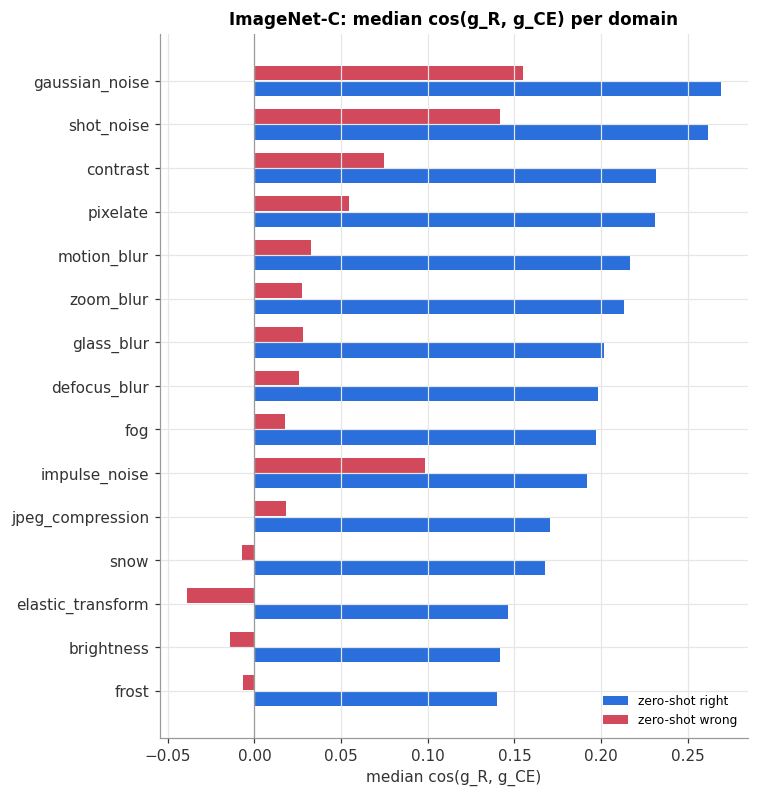

In [8]:
for k, a in A.items():
    ga.domain_figure(a, REC[k]["domain_idx"], NAMES[k], f"{k}: median cos(g_R, g_CE) per domain"); plt.show()

## Finding 2b: histograms of the same cosines, by zero-shot outcome
Share of samples per cosine bin; dashed lines are medians. Top figure per dataset: Ramen's g_R against the shuffled null and the own entropy gradient g_H. Bottom: g_R before and after the sign.

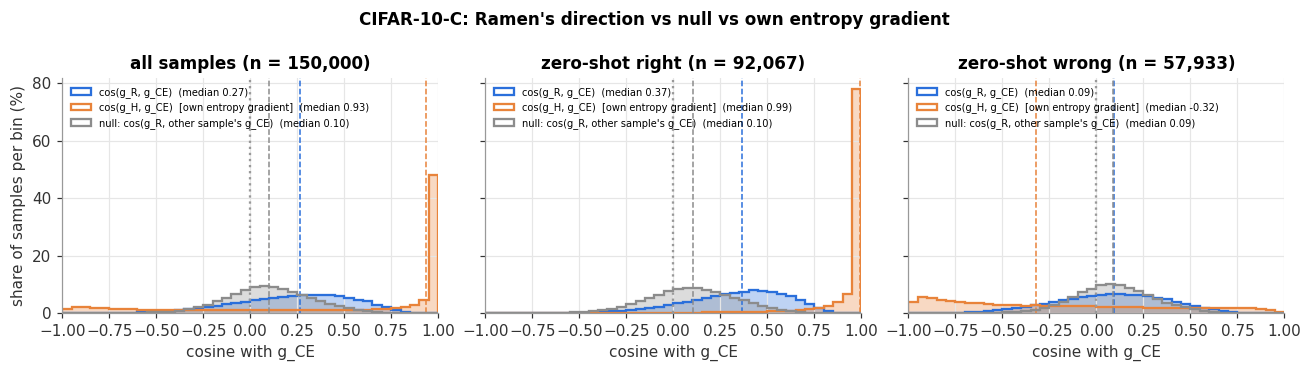

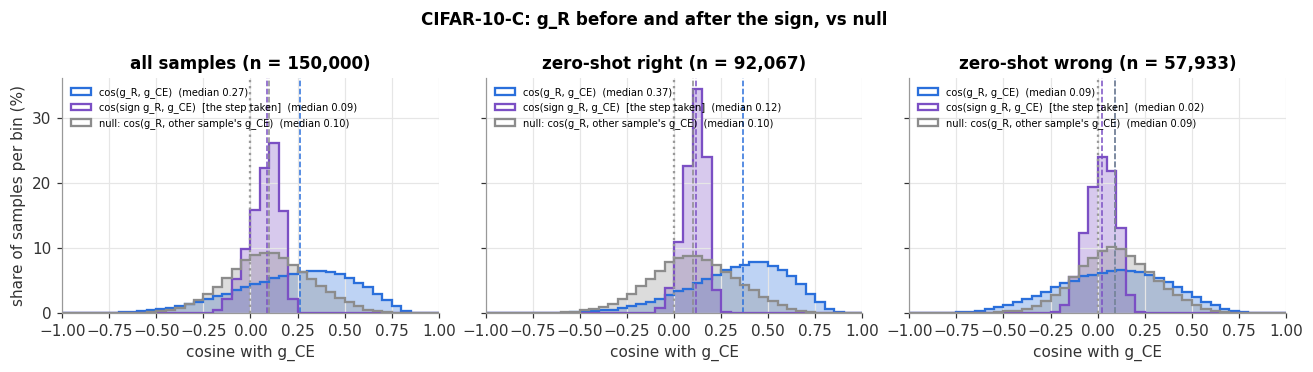

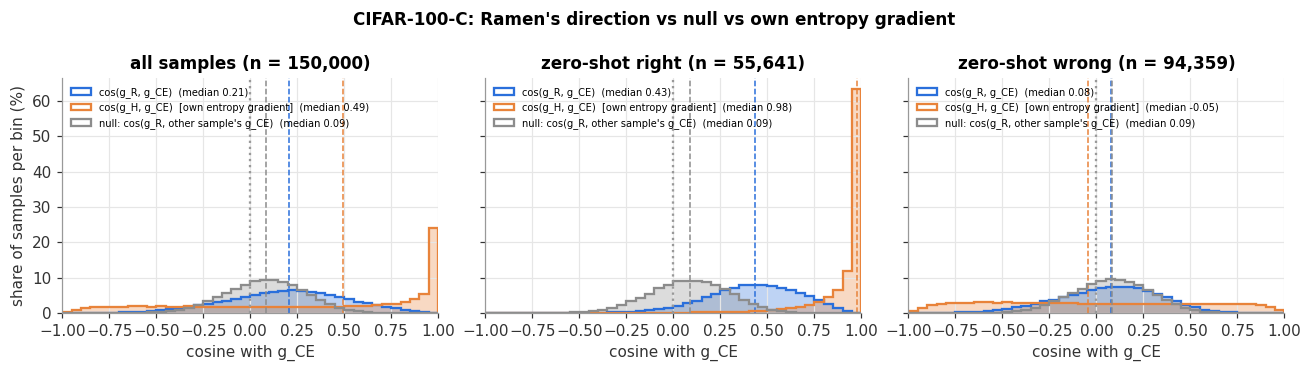

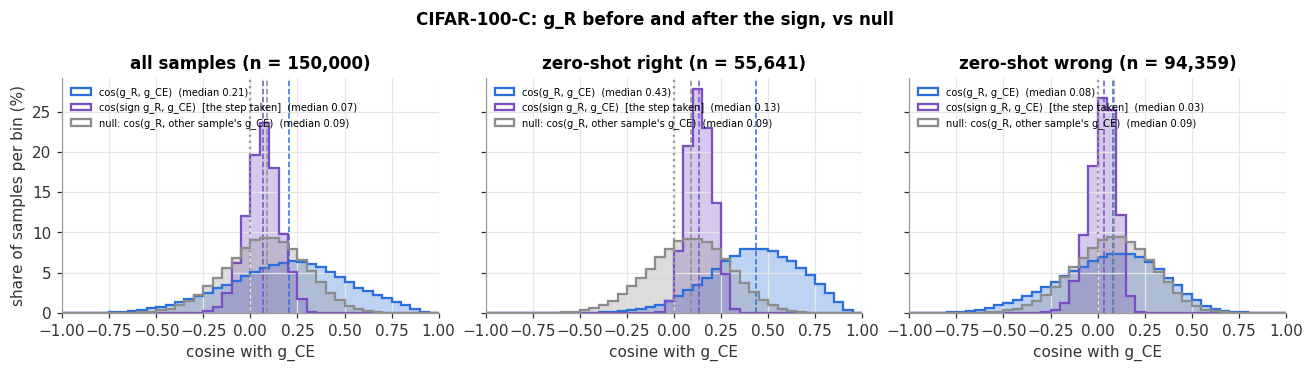

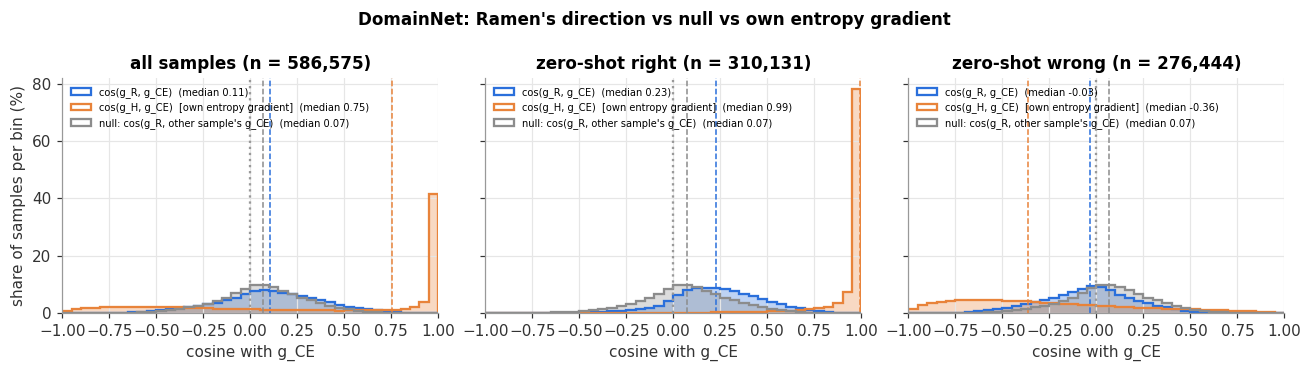

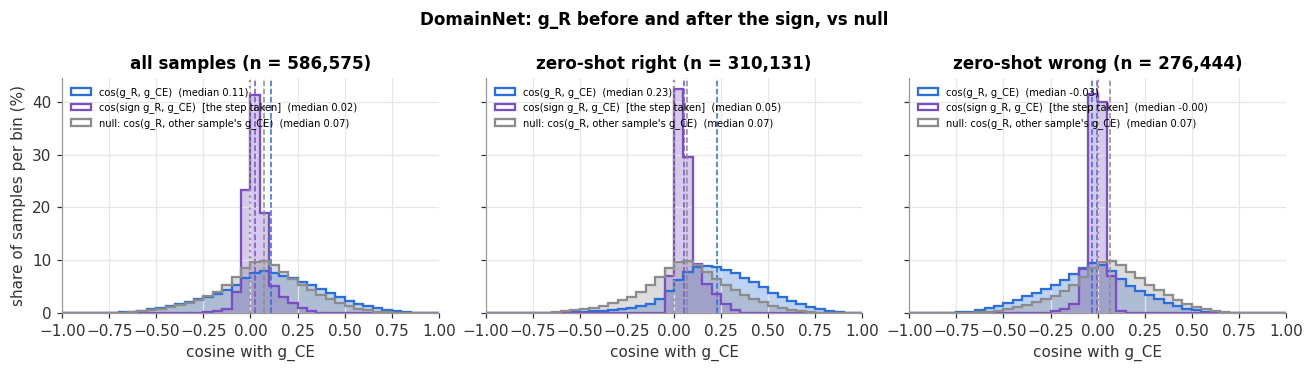

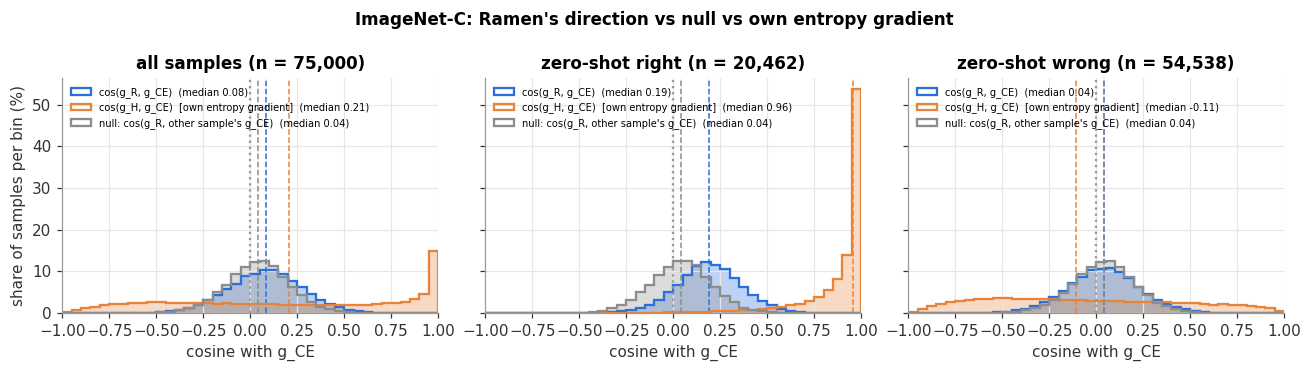

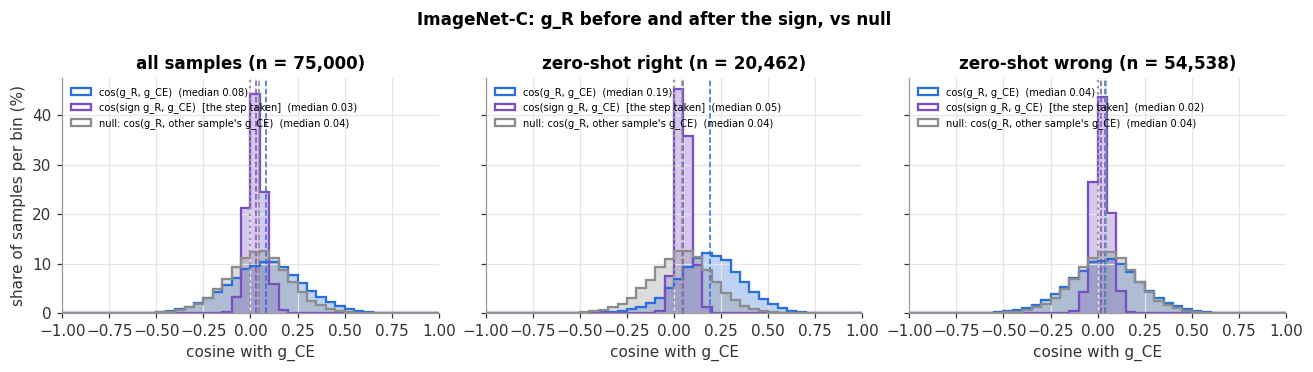

In [9]:
for k, a in A.items():
    ga.histogram_figure(a, f"{k}: Ramen's direction vs null vs own entropy gradient"); plt.show()
    ga.histogram_figure(a, f"{k}: g_R before and after the sign, vs null", keys=("cos_R_CE", "cos_signR_CE", "cos_R_CEnull")); plt.show()

## Finding 3: per layer, the agreement is carried by particular LayerNorms; the own entropy gradient is near-perfect on right samples and negative on wrong ones

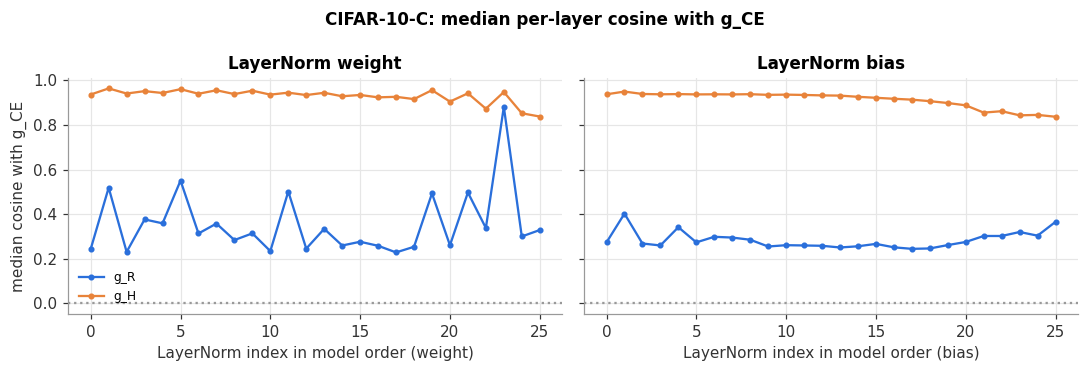

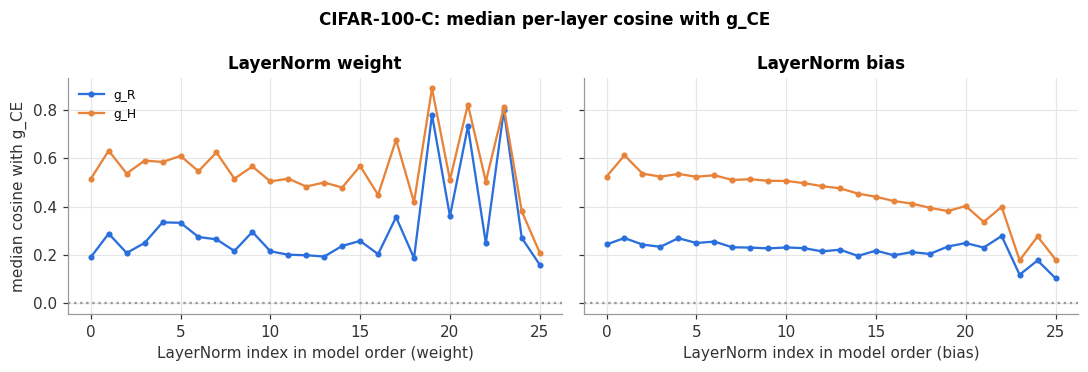

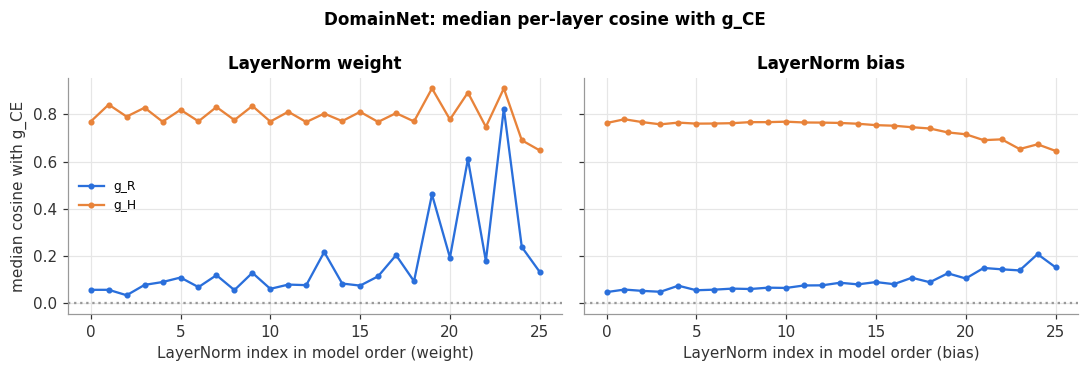

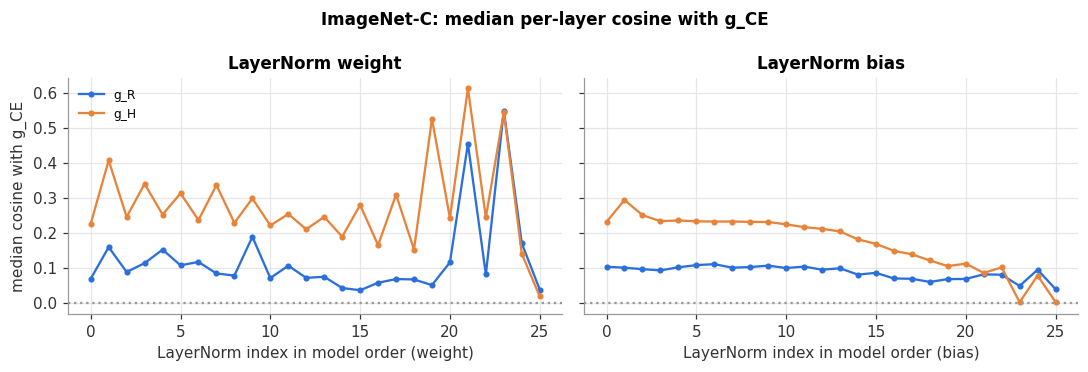

In [10]:
for k, a in A.items():
    ga.layer_figure(a, f"{k}: median per-layer cosine with g_CE"); plt.show()

## Finding 4: along the stream the cosine is nearly flat on CIFAR, rises on ImageNet-C and falls on DomainNet; a higher cosine goes with a larger CE drop

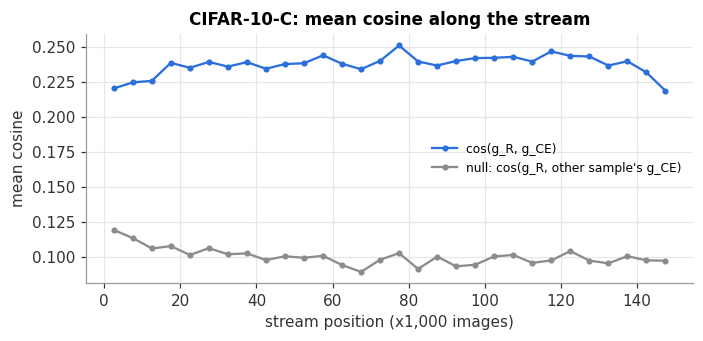

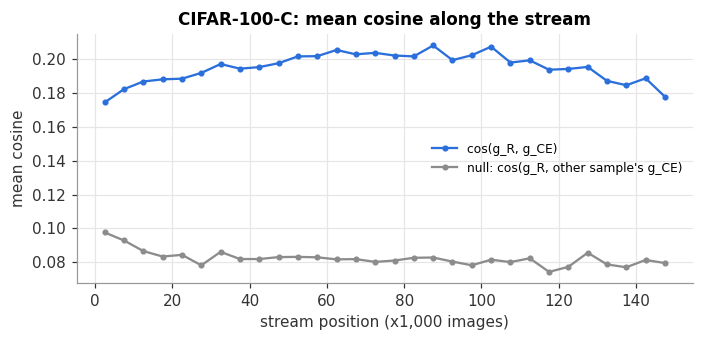

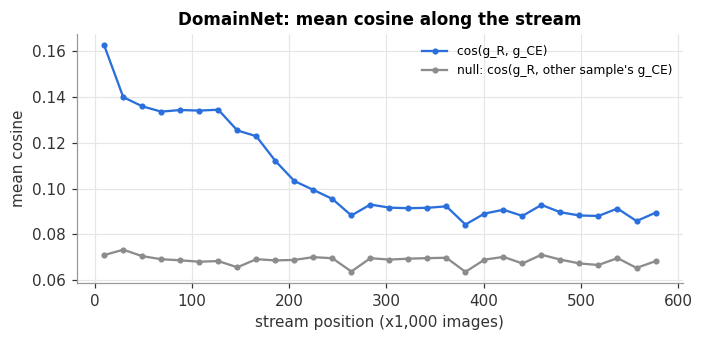

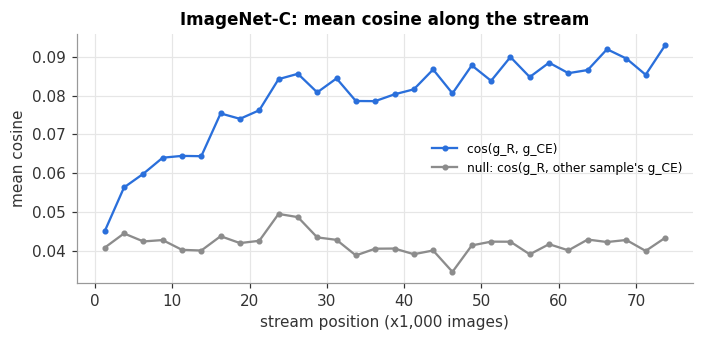

In [11]:
for k, a in A.items():
    ga.stream_figure(a, f"{k}: mean cosine along the stream"); plt.show()

In [12]:
rows = []
for k, a in A.items():
    ok = ~np.isnan(a["cos_R_CE"]); d = a["ce_after"] - a["ce_before"]
    rows.append({"dataset": k, "mean CE change": round(float(d.mean()), 3), "samples with CE lower after": f"{int((d<0).sum()):,} of {len(d):,} ({(d<0).mean():.1%})",
                 "corr(cos, CE change)": round(float(np.corrcoef(a['cos_R_CE'][ok], d[ok])[0, 1]), 3),
                 "sign agreement g_R vs g_CE": round(float(np.nanmean(a["agree_signR_CE"])), 3)})
pd.DataFrame(rows).set_index("dataset")

,mean CE change,samples with CE lower after,"corr(cos, CE change)",sign agreement g_R vs g_CE
dataset,,,,
CIFAR-10-C,-0.226,"116,340 of 150,000 (77.6%)",-0.293,0.574
CIFAR-100-C,-0.341,"106,430 of 150,000 (71.0%)",-0.318,0.564
DomainNet,0.108,"396,743 of 586,575 (67.6%)",-0.322,0.532
ImageNet-C,-0.411,"49,619 of 75,000 (66.2%)",-0.265,0.523


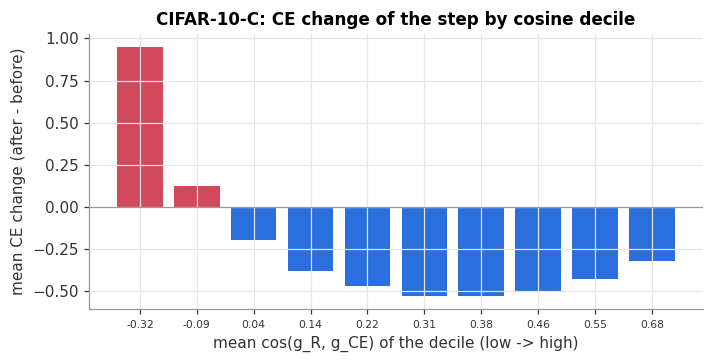

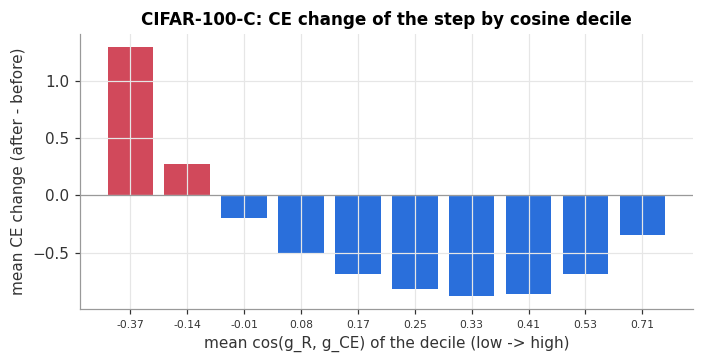

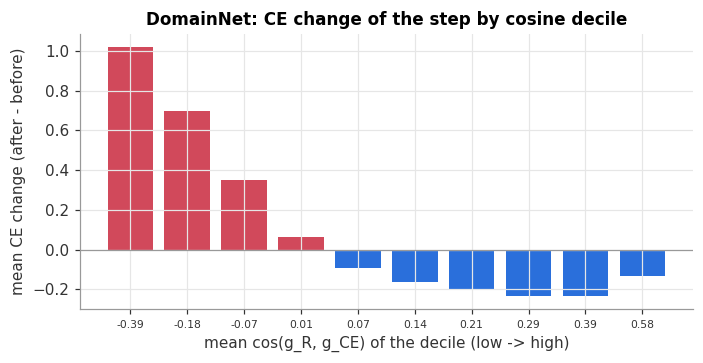

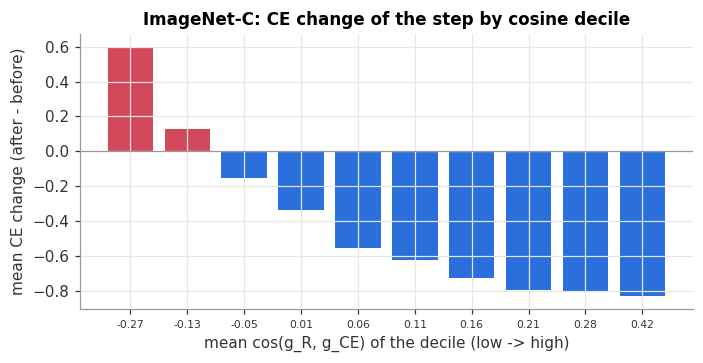

In [13]:
for k, a in A.items():
    ga.ce_change_figure(a, f"{k}: CE change of the step by cosine decile"); plt.show()

## Interpretation

**What the numbers say.**
- For most samples (roughly two thirds to four fifths, see Finding 1) Ramen's aggregated gradient has a positive cosine with the CE gradient, so a descent step also lowers CE to first order. The median cosine is small (largest on CIFAR-10-C, smallest on ImageNet-C), and it shrinks again after taking the sign, because SignSGD keeps only the sign of each coordinate: sign agreement is only a little above one half.
- Part of this is not sample-specific. The shuffled null (another sample's CE gradient) is already positive, so a share of the alignment comes from a direction common to all samples in the stream. The gap over the null is the sample-specific part, and it is a fraction of the total.
- Finding 2 splits the population. On samples zero-shot CLIP already classifies correctly, the sample's own entropy gradient is almost the CE gradient (cosine near 1), and Ramen's aggregate is clearly above the null. On zero-shot-wrong samples the own entropy gradient points away from CE (negative median on CIFAR-10-C and DomainNet), and Ramen's aggregate sits near the null, or below it on DomainNet. So the memory average turns a wrong-pointing own gradient into a roughly neutral one, but it does not point toward the true label.
- Finding 4 (stream): the mean cosine is nearly flat after a short start on the CIFAR sets (slightly lower in the first tenth), rises over the first half of the stream on ImageNet-C (what a cold memory would do), and falls on DomainNet. The DomainNet fall is not explained by this experiment [hypothesis: the memory fills with entries from the large, hard domains].
- Finding 4 (CE): higher cosine goes with a larger CE decrease (negative correlation between cosine and CE change on all four datasets), so the first-order picture is not empty. Average CE change is negative on three datasets and positive on DomainNet.

**What they do not say.**
- Seed 0 only, no seed spread, so no claim about small differences between datasets. The test runs for CIFAR-100-C and ImageNet-C were on the other GPU model, so their predictions differ slightly from the baseline run.
- The CE gradient uses the true label, so this is a diagnostic, not a method. It does not show that moving closer to $g^{CE}$ would raise accuracy; it measures the existing step.
- Cosine is computed over all 40k-odd LayerNorm coordinates; a different parameter subset, or a different norm, could rank layers differently.

**Mechanism, labelled.** [hypothesis] Ramen's weights $e^{-H_j}$ favour confident entries, which are mostly zero-shot right, so the aggregate inherits their (CE-aligned) direction; the wrong samples get the same average and therefore stay near the null. This was not tested directly, for example by splitting $g^R$ by the correctness of the retrieved entries.

**Next step and stop rule.** Split $g^R$ by the zero-shot correctness of the retrieved entries to test the hypothesis above. If the share of correct entries does not predict the cosine on wrong samples, drop the hypothesis. Whether a label-free change that raises this alignment also raises accuracy is a separate test and needs its own plan.

## Glossary
- **CE gradient $g^{CE}$:** gradient of the cross-entropy to the true label w.r.t. the sample's own LayerNorm affine parameters. ORACLE: uses labels.
- **Entropy gradient $g^{H}$:** the same for the prediction entropy; what Ramen stores in memory.
- **Aggregated gradient $g^{R}$:** Ramen's retrieved, weighted average of stored $g^{H}$; the quantity SignSGD steps on.
- **Cosine:** $a\cdot b/(\lVert a\rVert\lVert b\rVert)$, in $[-1,1]$; positive = same half-space.
- **Null:** cosine of $g^R_i$ with the CE gradient of a different sample in the batch. Measures sample-agnostic agreement.
- **Zero-shot right / wrong:** CLIP's prediction before any adaptation matches / does not match the true label.
- **Sign agreement:** share of coordinates where two gradients have the same sign.
- **First-order CE change:** $-\eta\langle \mathrm{sign}\,g^R, g^{CE}\rangle$; the realised change is `ce_after - ce_before` of the actual predictions.
- **Loss scale 1024:** the CE loss is multiplied by this before backward so fp16 gradients do not underflow, then divided back. Cosines are unchanged by it.
- **Mixed stream / ORACLE / noise floor:** as in `docs/GUIDE.md`. No noise floor is applied here (single seed, diagnostic).